# 05.4 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/04-xgboost-lightgbm/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

In [2]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]
cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

def cv_auc(model):
    """Mean 5-fold cross-validated AUC on the training customers."""
    return cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()

def test_auc(model):
    """Fit on all training customers, score AUC on the held-out test customers."""
    model.fit(X_train, y_train)
    return roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

print(f"Benchmark logistic regression: CV AUC {cv_auc(logreg):.3f}, test AUC {test_auc(logreg):.3f}")

import time
import xgboost as xgb
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier

def make_models():
    return {
        "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=42, n_jobs=4),
        "XGBoost": xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                                     colsample_bytree=0.8, random_state=42, n_jobs=4),
        "LightGBM": lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=8, min_child_samples=30,
                                       subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                       random_state=42, n_jobs=4, verbose=-1),
    }

Benchmark logistic regression: CV AUC 0.740, test AUC 0.741


## Exercise 1

In [4]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)
m = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, num_leaves=8, min_child_samples=30,
                       subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, n_jobs=4, verbose=-1)
m.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], eval_metric="auc",
      callbacks=[lgb.early_stopping(50, verbose=False)])
print(f"best round {m.best_iteration_}, test AUC {roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]):.3f}")

best round 16, test AUC 0.732


Like XGBoost, LightGBM stops early on this small, noisy table, after a few dozen rounds, and lands close to the logistic benchmark. Same lesson: the number of useful trees is small when there is little structure to learn.

## Exercise 2

In [5]:
for d in [1, 2, 3, 6, 10]:
    m = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=d, subsample=0.8,
                          colsample_bytree=0.8, random_state=42, n_jobs=4)
    print(f"churn, max_depth={d:>2}: CV AUC {cv_auc(m):.3f}")

churn, max_depth= 1: CV AUC 0.741


churn, max_depth= 2: CV AUC 0.732


churn, max_depth= 3: CV AUC 0.723


churn, max_depth= 6: CV AUC 0.710


churn, max_depth=10: CV AUC 0.701


Shallow trees do as well as or better than deep ones on churn, and deep trees are worst. Stumps cannot model interactions at all, so if they are competitive, the churn signal is mostly **additive**: each feature pushes the risk up or down on its own. That is the same reason logistic regression does so well here.

## Exercise 3

In [6]:
def make_orders(n, seed=0):
    """Orders like lesson 00.1: fraud = big order from a new account, OR very big order to a mismatched country."""
    rng = np.random.default_rng(seed)
    total = rng.gamma(2.0, 150, n)
    account_days = rng.integers(1, 1000, n)
    account_days = np.where(rng.random(n) < 0.25, rng.integers(1, 15, n), account_days)
    items = rng.integers(1, 15, n)
    country_match = rng.choice([0, 1], n, p=[0.15, 0.85])
    truth = ((total > 300) & (account_days < 10)) | ((country_match == 0) & (total > 500))
    fraud = (truth ^ (rng.random(n) < 0.03)).astype(int)        # 3% label noise
    return pd.DataFrame({"total": total, "account_days": account_days, "items": items,
                         "country_match": country_match, "fraud": fraud})

orders = make_orders(20_000)
fX, fy = orders.drop(columns="fraud"), orders["fraud"]
fX_train, fX_test, fy_train, fy_test = train_test_split(fX, fy, test_size=0.25, random_state=42, stratify=fy)
for d in [1, 2, 3, 6, 10]:
    m = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=d, random_state=42, n_jobs=4)
    m.fit(fX_train, fy_train)
    print(f"fraud, max_depth={d:>2}: test AUC {roc_auc_score(fy_test, m.predict_proba(fX_test)[:, 1]):.3f}")

fraud, max_depth= 1: test AUC 0.878
fraud, max_depth= 2: test AUC 0.873


fraud, max_depth= 3: test AUC 0.874


fraud, max_depth= 6: test AUC 0.876


fraud, max_depth=10: test AUC 0.880


Surprise: stumps are almost as good as deep trees here (all depths land around 0.87–0.88), and miles ahead of logistic regression (0.815). Why? Boosting **adds up** many stumps in log-odds space. "Total over £300" adds a big push towards fraud, "account under 10 days" adds another; customers with *both* pushes end up far higher than customers with one. Adding large pushes behaves a lot like "and".

So what logistic regression was missing on fraud was not mainly the interaction but the **shape**: a cliff at 10 days instead of a gentle slope over 1,000 days. Boosted stumps can draw cliffs; a straight line cannot. Depth matters more when interactions are subtle, for example "a big order is risky for new accounts but *safe* for old ones".

## Exercise 4

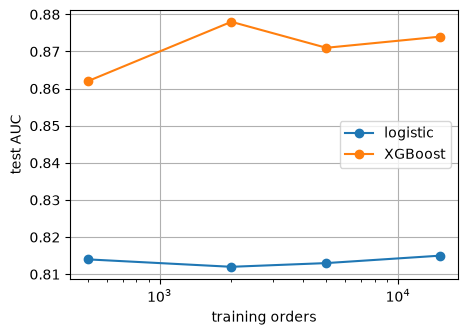

,logistic,XGBoost
500,0.814,0.862
2000,0.812,0.878
5000,0.813,0.871
15000,0.815,0.874


In [7]:
sizes = [500, 2000, 5000, 15000]
res = {"logistic": [], "XGBoost": []}
for n in sizes:
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(fX_train[:n], fy_train[:n])
    xg = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42, n_jobs=4).fit(fX_train[:n], fy_train[:n])
    res["logistic"].append(roc_auc_score(fy_test, lr.predict_proba(fX_test)[:, 1]))
    res["XGBoost"].append(roc_auc_score(fy_test, xg.predict_proba(fX_test)[:, 1]))
pd.DataFrame(res, index=sizes).round(3).plot(marker="o", logx=True, figsize=(5, 3.5),
                                             xlabel="training orders", ylabel="test AUC", grid=True)
plt.show(); pd.DataFrame(res, index=sizes).round(3)

Logistic regression is flat at about 0.81 from 500 orders to 15,000: it found the best straight line early and more data cannot change its shape. XGBoost is already ahead at 500 orders, jumps at 2,000, then levels off around 0.87–0.88. That ceiling is the 3% of labels we flipped at random: no model can predict pure noise. Two lessons: flexible models need *enough* data to place their thresholds, and every dataset has a noise ceiling that no amount of modelling will break.